# Awareness layer under a regime holdout

**Question.** A controller needs three answers per window, not one: is this movement
*unfamiliar* (novelty), *which regime* does it resemble (regime), and *can the active prediction
be trusted* (reliability)? This notebook computes those three signals from one sensor window and
lays them out side by side, per task, under a holdout that removes an **entire regime** from
training: `DOWN` holds out ramp descent, stair descent, standing and transitions, so training sees
level ground, ramp ascent and stair ascent only. The six existing models are run under the same
holdout for a model-by-model comparison.

Code and tracked results live in [`ml/awareness/`](../../ml/awareness/README.md); nothing here
trains. Scores are shown as **spreads by task with no thresholds**: this is the raw material for
deciding what to fuse, not a detector.

Read top-to-bottom: split → encoder and novelty → regime probes → forecaster → baselines → all
scores by task.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'ml/vanilla/registry.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter within this repository.')
sys.path.insert(0, str(ROOT / 'notebooks/model_exploration'))
get_ipython().run_line_magic('matplotlib', 'inline')
from _exploration import *
import torch
from dataclasses import asdict
torch.set_num_threads(2)  # small architecture checks; training CLI runs separately
torch.manual_seed(0)
RUN_TRAINING = False
print('Repository:', ROOT)
print('Kernel:', sys.executable)

Repository: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton
Kernel: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python


## The holdout

`ml/LOTO/splits.py` names a holdout by the **set** of modes it removes. `DOWN` = {RD, SD, ST, TR}.
Participants, scaler, causal median filter (ten scores) and evaluators are the ones every other
run uses, so all rows below are computed on identical test windows: ID = LG, RA, SA of the four
test participants; OOD = the four held-out modes of the same participants.

$$\widetilde\Psi_t=\operatorname{median}(\Psi_{t-9},\ldots,\Psi_t)\qquad\text{for every score below.}$$

AUROC (OOD versus ID, and each held-out mode alone versus ID) is reported because it is a ranking
statistic with no threshold in it. Nothing in this notebook chooses an operating point.

In [2]:
from splits import build, held_out_modes, trained_modes
HOLDOUT = 'DOWN'
print('held out:', held_out_modes(HOLDOUT), ' trained on:', trained_modes(HOLDOUT))
_d = build('autoencoder', HOLDOUT, batch_size=256)
rows = []
for name in ('train', 'val', 'test'):
    by = _d.splits[name].meta.groupby('mode').size().to_dict()
    rows.append({'split': name, 'kind': 'ID', **by, 'total': len(_d.splits[name])})
    if name in _d.ood:
        by = _d.ood[name].meta.groupby('mode').size().to_dict()
        rows.append({'split': name, 'kind': 'OOD', **by, 'total': len(_d.ood[name])})
display(pd.DataFrame(rows).fillna(0).astype({c: int for c in ('total',)}).set_index(['split', 'kind']))
AW = ROOT / 'ml/awareness'
RUNS_AW = AW / 'runs' / HOLDOUT
RESULTS_AW = AW / 'results' / HOLDOUT

held out: ('RD', 'SD', 'ST', 'TR')  trained on: ['LG', 'RA', 'SA']


LG       RA       SA   total       RD       SD      ST  \
split kind                                                                
train ID    88390.0  55512.0  28625.0  172527      0.0      0.0     0.0   
val   ID    30942.0  18504.0   9367.0   58813      0.0      0.0     0.0   
      OOD       0.0      0.0      0.0   28881  14904.0   8654.0  1242.0   
test  ID    28668.0  18504.0  10273.0   57445      0.0      0.0     0.0   
      OOD       0.0      0.0      0.0   27554  14784.0  10155.0   621.0   

                TR  
split kind          
train ID       0.0  
val   ID       0.0  
      OOD   4081.0  
test  ID       0.0  
      OOD   1994.0

## Stage A: encoder and novelty

The encoder is `ml/VAE`'s deterministic configuration: the AE trunk with a **linear** 4×8 latent
head, trained on the unit-variance Gaussian NLL with β=0 and no sampling, at the AE's settings
(learning rate 0.003, batch 1,024, up to 200 epochs, patience 5, participant-disjoint early
stopping). Under the original protocol it gave the best latent-LOF ranking of anything tried
(test AUROC 0.822 against the vanilla AE's 0.782), which is why it is the encoder here.

$$z=E_\theta(x)\in\mathbb R^{32},\qquad \Psi_{\rm nov}(x)=\operatorname{LOF}_{20}(z)\ \text{fitted on 50,000 ID training latents},$$

and the same LOF refitted on 12 and 16 principal components of the same reference, since fewer
dimensions helped every model in the earlier post-hoc check. Reconstruction NLL is kept as a
separate diagnostic (it ranked OOD *below* ID under the original protocol).

**Artifact directory:** `ml/awareness/runs/DOWN/encoder`

,artifact,available
0,report.json,True
1,final.pt,True
2,eval_test.json,True
3,figures,False


,saved value
beta,0.0
lr,0.003
batch_size,1024
max_epochs,200
patience,5
seed,0
val_fraction,0.2
held_out,DOWN
device,None
max_train_windows,None


,saved result
best_epoch,23
smoke_run,False
latent_dim,32
internal early-stopping participants,"AB18, AB28"


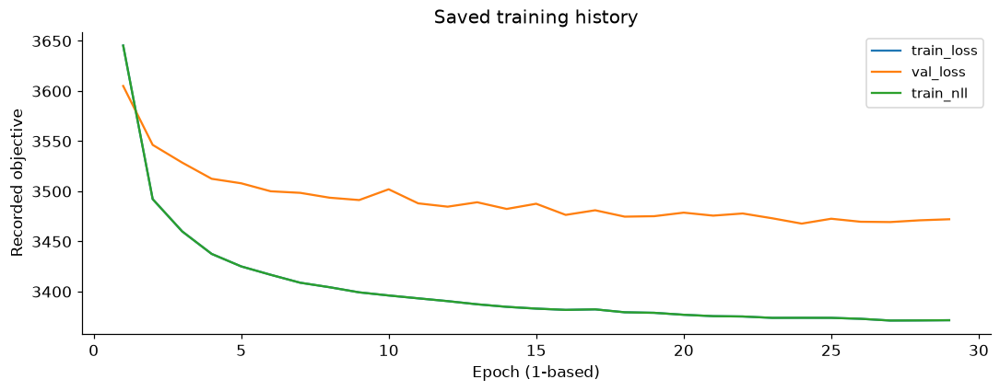

,epoch,train_loss,train_nll,train_kl,val_loss,val_nll,val_kl
24,24,3373.790931,3373.790931,9.287529,3472.642982,3472.642982,9.937988
25,25,3372.842805,3372.842805,10.016655,3469.635074,3469.635074,9.950867
26,26,3371.111516,3371.111516,9.896529,3469.333757,3469.333757,9.828654
27,27,3371.232579,3371.232579,9.936118,3471.079297,3471.079297,10.324350
28,28,3371.426805,3371.426805,10.612352,3472.122980,3472.122980,10.657333


,AUROC,recall (%),specificity (%),J (−1 to 1),threshold
score,,,,,
reconstruction_nll,0.4863,0.0000,99.6658,-0.0033,4401.9524
kl,0.1112,0.0000,99.3228,-0.0068,21.3539
negative_elbo,0.4800,0.0000,99.6553,-0.0034,4420.3003
latent_lof,0.9741,85.0258,96.6350,0.8166,1.3068


,mode,kind,windows,median_psi,flagged_%
0,LG,ID,28668,1.1039,4.1928
1,RA,ID,18504,1.0865,1.7348
2,SA,ID,10273,1.1039,3.9910
3,RD,OOD,14784,1.4097,83.9962
4,SD,OOD,10155,1.6677,91.3442
5,ST,OOD,621,1.8022,100.0000
6,TR,OOD,1994,1.3575,55.8175


In [3]:
ENC = RUNS_AW / 'encoder'
inventory(ENC)
config_and_history(ENC)
results_table(ENC)

### Interactive views of the encoder's test latents

UMAP and PCA fitted on **in-distribution** test latents (LG, RA, SA), every task transformed in;
the third panel is raw latent coordinates. Task colours are fixed; the four held-out modes are
simply the four tasks the encoder never saw. In 3-D one scene has a projection selector.

**Three projections of the same rows.** `umap` is nonlinear and neighbourhood-preserving:
distances, cluster areas and gaps are not measurements. `pca` is linear, fitted on the same
reference rows, and its axis labels carry the explained variance. `latent` is two or three raw
latent coordinates with no transformation at all: the only view in which a distance is a true
latent distance, at the price of showing 2-3 of 32 dimensions (`LATENT_DIMS = None` picks the
highest-variance ones on the reference rows; give a tuple such as `(0, 8, 16)` to choose).

**Layout.** In 2-D and in 3-D the projections are side-by-side panels of one figure (the VAE's
view buttons switch all panels together). Every 3-D panel is a WebGL scene, browsers allow only
about 8-16 live WebGL contexts per page, and JupyterLab is one page for every open notebook: a
three-panel 3-D figure costs three. If a 3-D panel ever shows its legend but a blank scene, close
the other notebook tabs and reload the page. 2-D maps are SVG and never hit that cap.

**How to move around (Plotly):** scroll to zoom, drag to pan (2-D) or rotate (3-D; right-drag
pans), double-click to reset. Click a task in the legend to hide it in every panel; double-click
a task to isolate it. Hover shows the participant and trial. `VIEW_DIMS` selects `(2,)`, `(3,)`
or `(2, 3)`; `PROJECTIONS` selects which projections appear. With `SAVE_HTML = True` each figure
is also written as a standalone page under `notebooks/model_exploration/interactive/` (ignored
by git) for full-screen browsing.

Every task keeps **one fixed colour and marker symbol**, whatever role a protocol assigns it.
UMAP embeddings are cached under `.cache/`; delete that folder to recompute.

In [4]:
from _umap_exploration import ae_latent_views
VIEW_DIMS = (2, 3)
PROJECTIONS = ('umap', 'pca', 'latent')
LATENT_DIMS = None
MAX_POINTS = 12_000
VIEW_SEED = 0
SAVE_HTML = True
if (ENC / 'latents_test.npz').exists():
    enc_views = ae_latent_views(ENC, dims=VIEW_DIMS, projections=PROJECTIONS, latent_dims=LATENT_DIMS,
                                max_points=MAX_POINTS, seed=VIEW_SEED, save_html=SAVE_HTML)
else:
    print('Encoder run not pulled yet:', ENC)

Standalone interactive copy: notebooks/model_exploration/interactive/ae_encoder_views_2d.html


Standalone interactive copy: notebooks/model_exploration/interactive/ae_encoder_views_3d.html


## Stage B: regime probes

Two probes read the same latent, trained on the **training split's task labels mapped to regimes**
(LG → level; RA, SA → ascend). Under `DOWN` those are the only two regimes, so a held-out window can
never be named "descend"; what is recorded is the probe's probabilities, its confidence (max
probability) and its entropy:

$$H(x)=-\sum_c p_c(x)\log p_c(x).$$

`logistic` is the linear probe (is regime linearly readable from the latent?); `mlp` (two hidden
layers of 64) is the comparison. Accuracy is meaningful only on ID windows; on the held-out modes
the interesting numbers are mean entropy and which known regime absorbs them.

In [5]:
REG = RUNS_AW / 'regime'
for probe in ('logistic', 'mlp'):
    f = REG / f'{probe}_summary.json'
    if not f.exists():
        print(probe, 'not available yet'); continue
    summary = read_json(f)
    display(Markdown(f'### {probe} probe — classes {summary["classes"]}, trained on {summary["n_train"]:,} latents'))
    acc = {k: v['accuracy'] for k, v in summary.items() if isinstance(v, dict) and 'accuracy' in v}
    display(pd.Series(acc, name='accuracy on windows with a known regime').to_frame().round(4))
    rows = []
    for key in ('test_id', 'test_ood'):
        for mode, r in summary[key]['by_mode'].items():
            rows.append({'split': key, 'mode': mode, 'windows': r['windows'], 'mean entropy': r['mean_entropy'],
                         'mean confidence': r['mean_confidence'], **{f'predicted {c}': v for c, v in r['predicted_share'].items()}})
    display(pd.DataFrame(rows).set_index(['split', 'mode']).round(3))

### logistic probe — classes ['ascend', 'level'], trained on 172,527 latents

,accuracy on windows with a known regime
train_id,0.8675
val_id,0.8571
val_ood,NaN
test_id,0.8910
test_ood,NaN


windows  mean entropy  mean confidence  predicted ascend  \
split    mode                                                             
test_id  LG      28668         0.406            0.810             0.156   
         RA      18504         0.250            0.901             0.954   
         SA      10273         0.206            0.915             0.909   
test_ood RD      14784         0.408            0.816             0.436   
         SD      10155         0.342            0.839             0.709   
         ST        621         0.023            0.997             0.000   
         TR       1994         0.339            0.835             0.107   

               predicted level  
split    mode                   
test_id  LG              0.844  
         RA              0.046  
         SA              0.091  
test_ood RD              0.564  
         SD              0.291  
         ST              1.000  
         TR              0.893

### mlp probe — classes ['ascend', 'level'], trained on 172,527 latents

,accuracy on windows with a known regime
train_id,0.9994
val_id,0.9727
val_ood,NaN
test_id,0.9105
test_ood,NaN


windows  mean entropy  mean confidence  predicted ascend  \
split    mode                                                             
test_id  LG      28668         0.053            0.978             0.175   
         RA      18504         0.003            0.999             0.998   
         SA      10273         0.005            0.998             0.991   
test_ood RD      14784         0.012            0.995             0.011   
         SD      10155         0.104            0.956             0.386   
         ST        621         0.000            1.000             0.000   
         TR       1994         0.108            0.953             0.240   

               predicted level  
split    mode                   
test_id  LG              0.825  
         RA              0.002  
         SA              0.009  
test_ood RD              0.989  
         SD              0.614  
         ST              1.000  
         TR              0.760

## Stage C: the 200 ms hip-angle forecast ensemble

The seven-TCN forecast ensemble of Experiment 5, driven through `ml/vanilla/main.py` exactly as the
LOTO runner drives it, twice: **plain** (16 sensor channels) and **regime-conditioned** (16 channels
plus the logistic probe's two class probabilities as constant channels). Branch disagreement $A$ is
available immediately; the realized error $E$ of the ensemble mean, and the mean branch error
$\bar E$, exist 200 ms later:

$$E=\bar E-A\qquad\text{(Krogh–Vedelsby, exact per window).}$$

On a held-out window the regime input is whichever known regime the probe assigned, with its
confidence; the forecast target itself is unchanged. The first pass uses one leave-one-subject-out
fold for epoch selection (`--folds 1`) instead of twelve, to get a result back in an hour.

### forecast_plain

**Artifact directory:** `ml/awareness/runs/DOWN/forecast_plain`

,artifact,available
0,report.json,True
1,final.pt,True
2,eval_test.json,True
3,figures,True


,saved value
lr,0.001
batch_size,1024
max_epochs,60
patience,10
seed,0
device,None
threshold_percentile,99.5
n_members,7
out_dir,/n/home04/dsattari/Uncertainty-Aware-Hip-Exosk...
loso_folds,1


,saved result
target,forecast_angle
horizon,40
threshold,0.019112
val_loss,0.048482
LOSO selected epochs,15


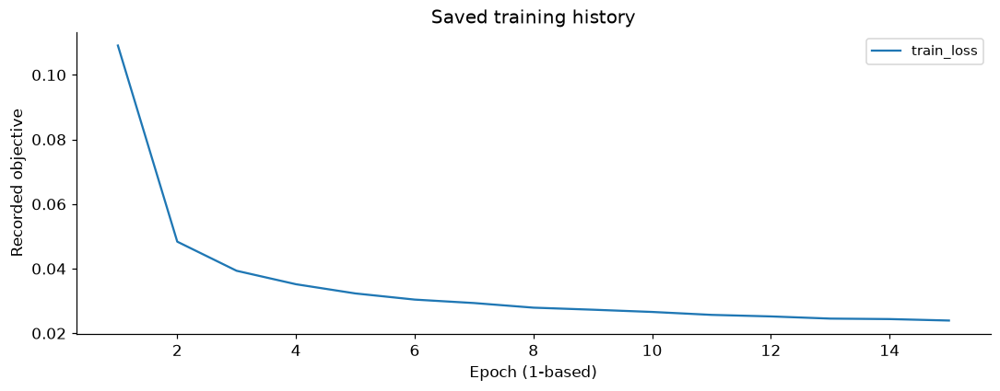

,epoch,train_loss,seconds
10,10,0.025673,14.9
11,11,0.025191,14.8
12,12,0.024517,14.9
13,13,0.024369,14.9
14,14,0.023917,14.9


**LOSO summary (epoch selection, not LOTO):**

{'n_epochs': 15,
 'folds': [{'subject': 'AB15',
   'best_epoch': 15,
   'val_loss': 0.04536235095117669,
   'epochs_run': 26}]}

,AUROC,recall (%),specificity (%),J (−1 to 1),threshold
score,,,,,
primary,0.8887,42.4076,98.8337,0.4124,0.0191


,mode,kind,windows,flagged_%,median_psi
0,LG,ID,28668,1.7302,0.0057
1,RA,ID,18504,0.0000,0.0068
2,SA,ID,10273,1.6938,0.0089
3,RD,OOD,14784,27.2998,0.0141
4,SD,OOD,10155,60.7779,0.0224
5,ST,OOD,621,100.0000,0.0421
6,TR,OOD,1994,42.9288,0.0139


### forecast_regime

**Artifact directory:** `ml/awareness/runs/DOWN/forecast_regime`

,artifact,available
0,report.json,True
1,final.pt,True
2,eval_test.json,True
3,figures,True


,saved value
lr,0.001
batch_size,1024
max_epochs,60
patience,10
seed,0
device,None
threshold_percentile,99.5
n_members,7
out_dir,/n/home04/dsattari/Uncertainty-Aware-Hip-Exosk...
loso_folds,1


,saved result
target,forecast_angle
horizon,40
threshold,0.02001
val_loss,0.047262
LOSO selected epochs,16


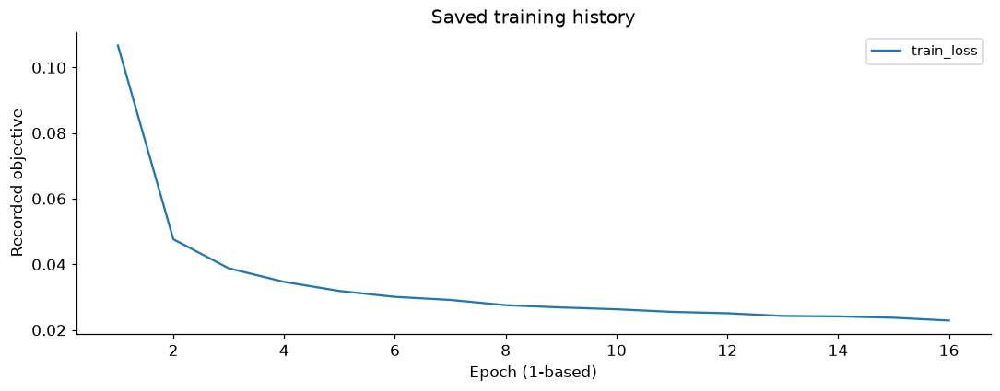

,epoch,train_loss,seconds
11,11,0.025113,15.3
12,12,0.024290,15.3
13,13,0.024165,15.2
14,14,0.023744,15.3
15,15,0.022888,15.3


**LOSO summary (epoch selection, not LOTO):**

{'n_epochs': 16,
 'folds': [{'subject': 'AB15',
   'best_epoch': 16,
   'val_loss': 0.046072247905808474,
   'epochs_run': 27}]}

,AUROC,recall (%),specificity (%),J (−1 to 1),threshold
score,,,,,
primary,0.862,35.6319,97.9824,0.3361,0.02


,mode,kind,windows,flagged_%,median_psi
0,LG,ID,28668,2.7382,0.0057
1,RA,ID,18504,0.0378,0.0069
2,SA,ID,10273,3.5725,0.0096
3,RD,OOD,14784,22.0779,0.0135
4,SD,OOD,10155,62.7179,0.0243
5,ST,OOD,621,0.0000,0.0127
6,TR,OOD,1994,9.2778,0.0097


In [6]:
for variant in ('plain', 'regime'):
    run = RUNS_AW / f'forecast_{variant}'
    display(Markdown(f'### forecast_{variant}'))
    inventory(run)
    config_and_history(run)
    results_table(run)

## Stage C′: regime experts, so the regime cannot be ignored

The conditioned forecaster turned out not to *use* its regime channels. The swap test below feeds
it the wrong regime on every window: on in-distribution windows the median realized error moves by
only a few percent, and on the held-out modes a wrong label even lowers it. On training data the
regime is already readable from the raw signal, so two constant input channels were never
load-bearing, and at test time a wrong value costs nothing.

Experts make the dependence structural. One ensemble is trained **per regime present in training**,
on that regime's windows only (`level` on LG, `ascend` on RA and SA); at inference the logistic
probe routes each window to an expert. A window from an unseen regime is routed to an expert that
never saw its dynamics, so its error rises by construction, and a new quantity appears: the
disagreement between the experts' mean forecasts.

$$E_{\rm routed}(x)=E_{c^*(x)}(x),\quad c^*(x)=\arg\max_c p_c(x);\qquad
E_{\min}(x)=\min_c E_c(x);\qquad
\Delta(x)=\big\|\bar f_{\rm level}(x)-\bar f_{\rm ascend}(x)\big\|^2/D.$$

Each expert sees roughly half the training windows, which is the price of this design.

**Swap test on the regime-conditioned forecaster** (median realized error per mode, true versus swapped regime input):

,true regime input,swapped regime input,ratio swapped / true
mode,,,
LG,0.0189,0.0202,1.0726
RA,0.0209,0.0220,1.0533
SA,0.0431,0.0427,0.9904
RD,0.0549,0.0518,0.9440
SD,0.0982,0.0934,0.9507
ST,0.0100,0.0074,0.7408
TR,0.0192,0.0195,1.0139


### expert_level

**Artifact directory:** `ml/awareness/runs/DOWN/expert_level`

,artifact,available
0,report.json,True
1,final.pt,True
2,eval_test.json,True
3,figures,True


,saved value
lr,0.001
batch_size,1024
max_epochs,60
patience,10
seed,0
device,None
threshold_percentile,99.5
n_members,7
out_dir,/n/home04/dsattari/Uncertainty-Aware-Hip-Exosk...
loso_folds,1


,saved result
target,forecast_angle
horizon,40
threshold,0.00745
val_loss,0.038953
LOSO selected epochs,26


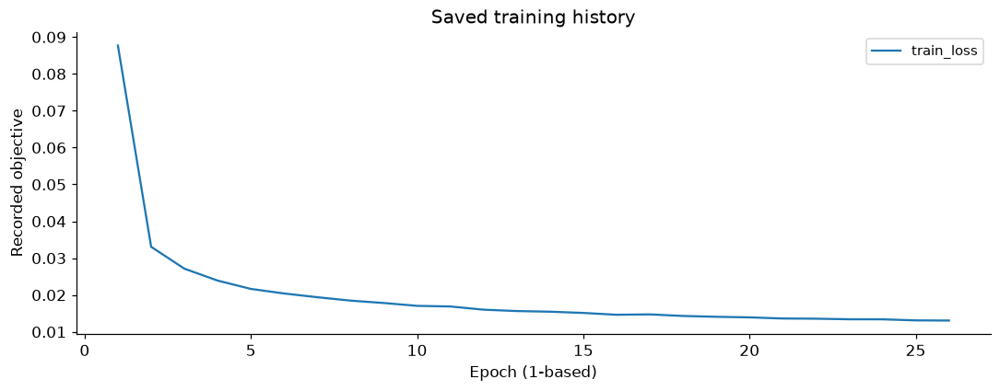

,epoch,train_loss,seconds
21,21,0.013560,7.7
22,22,0.013405,7.7
23,23,0.013390,7.7
24,24,0.013102,7.7
25,25,0.013062,7.7


**LOSO summary (epoch selection, not LOTO):**

{'n_epochs': 26,
 'folds': [{'subject': 'AB15',
   'best_epoch': 26,
   'val_loss': 0.032579079787890944,
   'epochs_run': 37}]}

,AUROC,recall (%),specificity (%),J (−1 to 1),threshold
score,,,,,
primary,0.9076,80.9356,87.3587,0.6829,0.0074


,mode,kind,windows,flagged_%,median_psi
0,LG,ID,28668,12.6413,0.0044
1,RD,OOD,14784,74.3439,0.0112
2,SD,OOD,10155,93.4712,0.0162
3,ST,OOD,621,100.0000,0.0442
4,TR,OOD,1994,60.0301,0.0110


### expert_ascend

**Artifact directory:** `ml/awareness/runs/DOWN/expert_ascend`

,artifact,available
0,report.json,True
1,final.pt,True
2,eval_test.json,True
3,figures,True


,saved value
lr,0.001
batch_size,1024
max_epochs,60
patience,10
seed,0
device,None
threshold_percentile,99.5
n_members,7
out_dir,/n/home04/dsattari/Uncertainty-Aware-Hip-Exosk...
loso_folds,1


,saved result
target,forecast_angle
horizon,40
threshold,0.026918
val_loss,0.061875
LOSO selected epochs,26


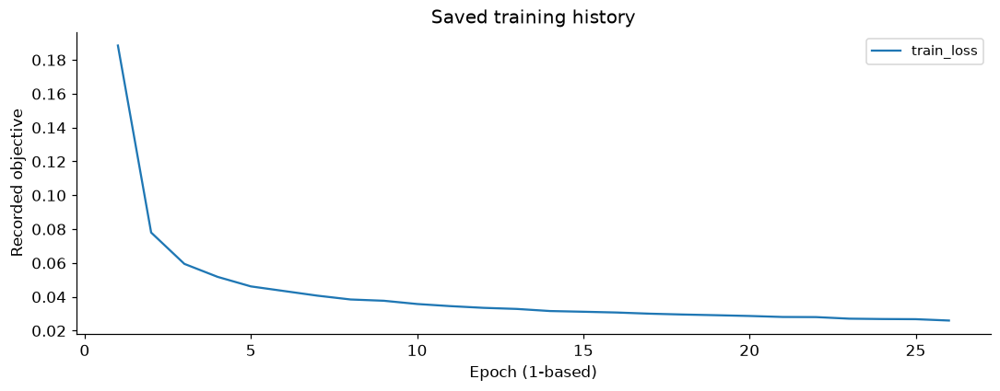

,epoch,train_loss,seconds
21,21,0.028025,7.4
22,22,0.027097,7.4
23,23,0.026881,7.4
24,24,0.026789,7.4
25,25,0.025993,7.4


**LOSO summary (epoch selection, not LOTO):**

{'n_epochs': 26,
 'folds': [{'subject': 'AB15',
   'best_epoch': 26,
   'val_loss': 0.05738693682413944,
   'epochs_run': 37}]}

,AUROC,recall (%),specificity (%),J (−1 to 1),threshold
score,,,,,
primary,0.9703,58.3037,99.2633,0.5757,0.0269


,mode,kind,windows,flagged_%,median_psi
0,RA,ID,18504,0.0000,0.0071
1,SA,ID,10273,2.0637,0.0107
2,RD,OOD,14784,51.1837,0.0272
3,SD,OOD,10155,66.9325,0.0343
4,ST,OOD,621,100.0000,0.0938
5,TR,OOD,1994,54.1625,0.0310


**Expert scores, test AUROC (OOD versus ID), and the share of windows routed to each expert:**

,AUROC
expert_ascend_error,0.7997
expert_level_error,0.5248
expert_ascend_disagreement,0.9515
expert_level_disagreement,0.7569
expert_routed_error,0.8096
expert_routed_disagreement,0.8612
expert_min_error,0.8108
expert_gap,0.3803


,routed share
ascend,0.533
level,0.467


In [7]:
swap = RESULTS_AW / 'regime_swap_test.csv'
if swap.exists():
    display(Markdown('**Swap test on the regime-conditioned forecaster** (median realized error per mode, true versus swapped regime input):'))
    display(pd.read_csv(swap, index_col=0).round(4))
else:
    print('Run `python ml/awareness/experts.py swap-test --holdout DOWN` to create', swap.name)
for regime in ('level', 'ascend'):
    run = RUNS_AW / f'expert_{regime}'
    display(Markdown(f'### expert_{regime}'))
    inventory(run)
    config_and_history(run)
    results_table(run)
summary = RUNS_AW / 'experts' / 'summary.json'
if summary.exists():
    s = read_json(summary)
    display(Markdown('**Expert scores, test AUROC (OOD versus ID), and the share of windows routed to each expert:**'))
    display(pd.Series({k: v for k, v in s.items() if isinstance(v, float)}, name='AUROC').to_frame().round(4))
    display(pd.Series(s['routed_share'], name='routed share').to_frame().round(3))
else:
    print('Expert scores not computed yet: pull both experts, then `python ml/awareness/experts.py score --holdout DOWN`.')

## The six existing models under the same holdout

Each row is one LOTO leaf, `ml/LOTO/DOWN/<model>`, trained on LG/RA/SA and scored on the same test
windows. AUROC is ranking; recall and false alarms are at each model's own training-percentile
threshold and are shown for completeness only.

In [8]:
rows = []
for leaf in ('vanilla/AE', 'vanilla/GAN', 'vanilla/Ensemble_GP', 'vanilla/Ensemble_synthetic', 'vanilla/Ensemble_forecast', 'prob_ensemble/run'):
    r = read_json(ROOT / 'ml/LOTO' / HOLDOUT / leaf / 'eval_test.json')
    if not r:
        rows.append({'model': leaf, 'status': 'not finished'}); continue
    for score, m in r.get('scores', {'primary': r.get('metrics', {})}).items():
        rows.append({'model': leaf, 'score': score, 'AUROC': m.get('auroc'), 'recall %': m.get('recall'),
                     'ID false alarms %': 100 - m.get('specificity', 100), 'status': 'done'})
display(pd.DataFrame(rows).round(4))

,model,score,AUROC,recall %,ID false alarms %,status
0,vanilla/AE,primary,0.9764,82.0788,1.5389,done
1,vanilla/GAN,primary,0.9377,33.0805,0.3029,done
2,vanilla/Ensemble_GP,primary,0.8779,2.9549,0.4705,done
3,vanilla/Ensemble_synthetic,primary,0.8836,48.5084,2.6565,done
4,vanilla/Ensemble_forecast,primary,0.8806,38.1106,1.6120,done
5,prob_ensemble/run,epistemic,0.8589,24.6716,0.8147,done
6,prob_ensemble/run,aleatoric,0.6431,0.1415,0.0696,done
7,prob_ensemble/run,total,0.7707,1.1759,0.3656,done
8,prob_ensemble/run,ratio,0.8654,35.4177,2.0332,done


## Every score, by task

`ml/awareness/aw_scores.py` aligns every per-window score to the same test windows (the gait-phase
ensemble keeps its own labelled window set) and `aw_plots.py` draws one violin per task per score:
**orange = never seen in training, blue = trained on**. Black bars are the interquartile range, the
tick the median; axes span the central 99.6 % of all windows. The table gives per-mode medians and
threshold-free AUROCs. Set `RECOMPUTE_SCORES = True` to rebuild both from the pulled runs (a few
minutes: LOF refits and the forecast error decomposition from the checkpoints); otherwise the
tracked files under `ml/awareness/results/` are shown.

score,windows,AUROC OOD vs ID,AUROC RD vs ID,AUROC SD vs ID,AUROC ST vs ID,AUROC TR vs ID
novelty_lof32,84999,0.974100,0.979400,0.983000,0.997600,0.882400
recon_nll,84999,0.486300,0.571700,0.466800,0.002600,0.103700
novelty_lof_pca12,84999,0.956500,0.952500,0.983100,0.997600,0.837900
novelty_lof_pca16,84999,0.957600,0.955700,0.981300,0.997600,0.838500
regime_logistic_p_ascend,84999,0.433800,0.373400,0.591300,0.005000,0.212400
regime_logistic_p_level,84999,0.566200,0.626600,0.408700,0.995000,0.787600
regime_logistic_confidence,84999,0.440300,0.384100,0.484000,0.906100,0.489000
regime_logistic_entropy,84999,0.559700,0.615900,0.516000,0.093900,0.511000
regime_mlp_p_ascend,84999,0.263900,0.173700,0.401500,0.113800,0.279300
regime_mlp_p_level,84999,0.741000,0.826300,0.611700,0.886200,0.720800


**Per-mode medians (each score in its own units):**

score,median LG,median RA,median RD,median SA,median SD,median TR,median ST
novelty_lof32,1.103900,1.086500,1.409700,1.103900,1.667700,1.357500,1.802200
recon_nll,3408.497200,3422.285000,3394.290700,3252.377300,3358.645400,3120.589600,3078.538200
novelty_lof_pca12,1.039600,1.042700,1.335900,1.095200,1.787300,1.286400,2.368100
novelty_lof_pca16,1.048700,1.047900,1.323000,1.096500,1.695400,1.278600,2.150300
regime_logistic_p_ascend,0.171000,0.951600,0.378100,0.978700,0.802800,0.124100,0.003400
regime_logistic_p_level,0.829000,0.048400,0.621900,0.021300,0.197200,0.875900,0.996600
regime_logistic_confidence,0.840000,0.951600,0.854300,0.979100,0.894300,0.880200,0.996600
regime_logistic_entropy,0.439600,0.193700,0.415200,0.101500,0.337400,0.366600,0.022600
regime_mlp_p_ascend,0.000000,1.000000,0.000000,1.000000,0.035700,0.000100,0.000000
regime_mlp_p_level,1.000000,0.000000,1.000000,0.000000,0.964300,0.999900,1.000000


### novelty

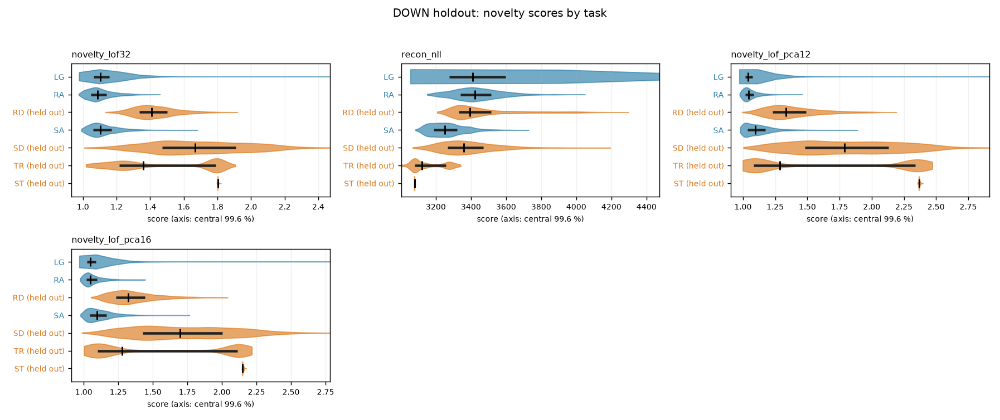

### regime

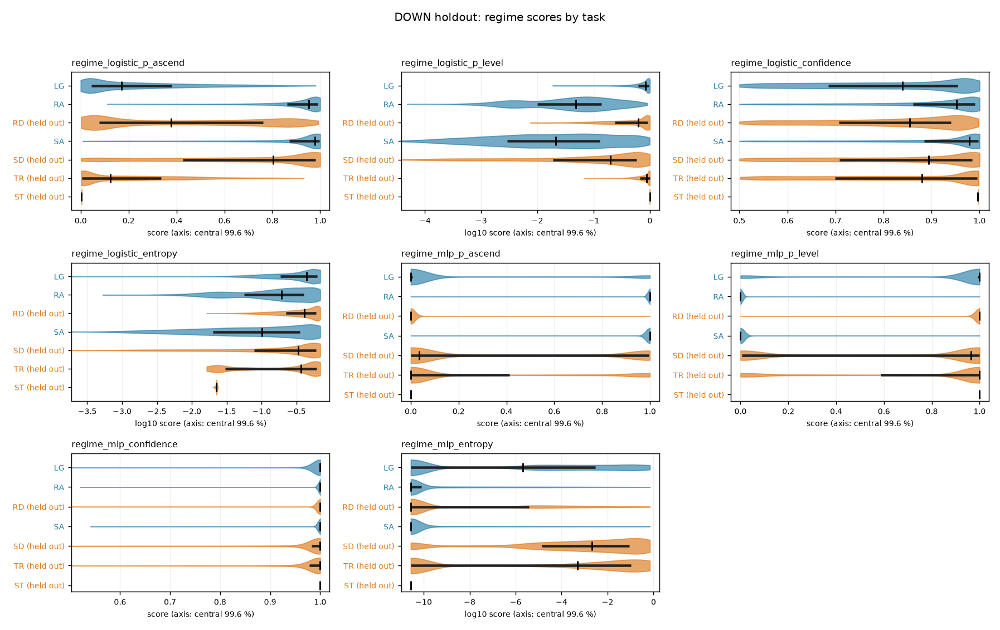

### forecast

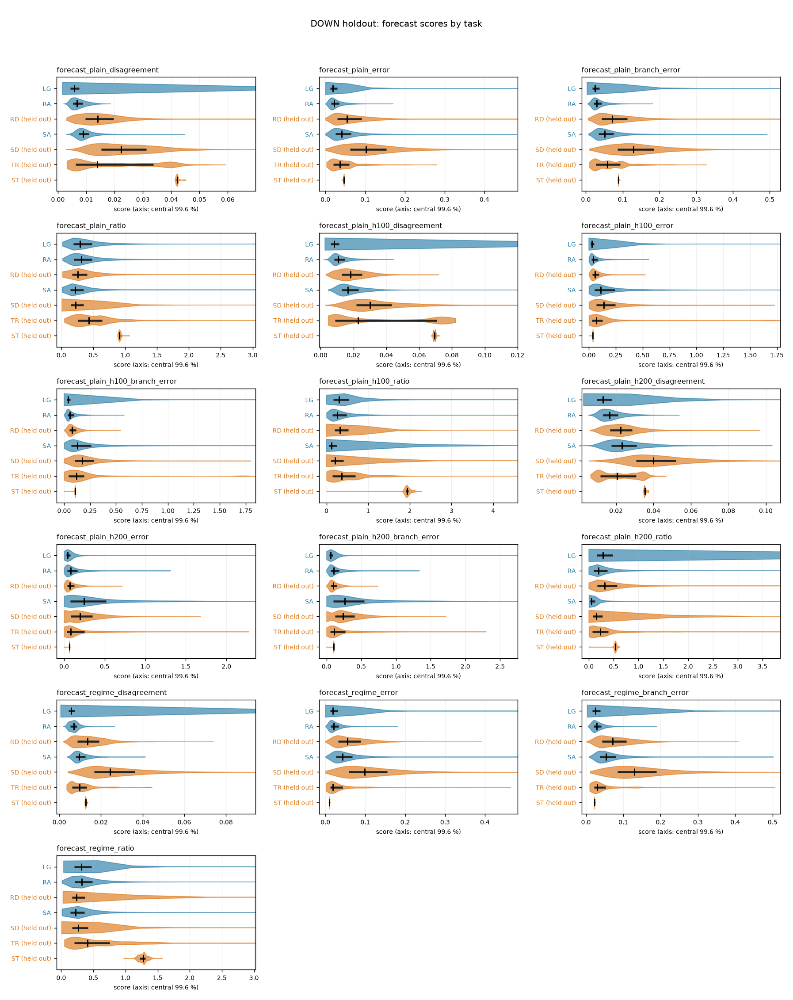

### experts

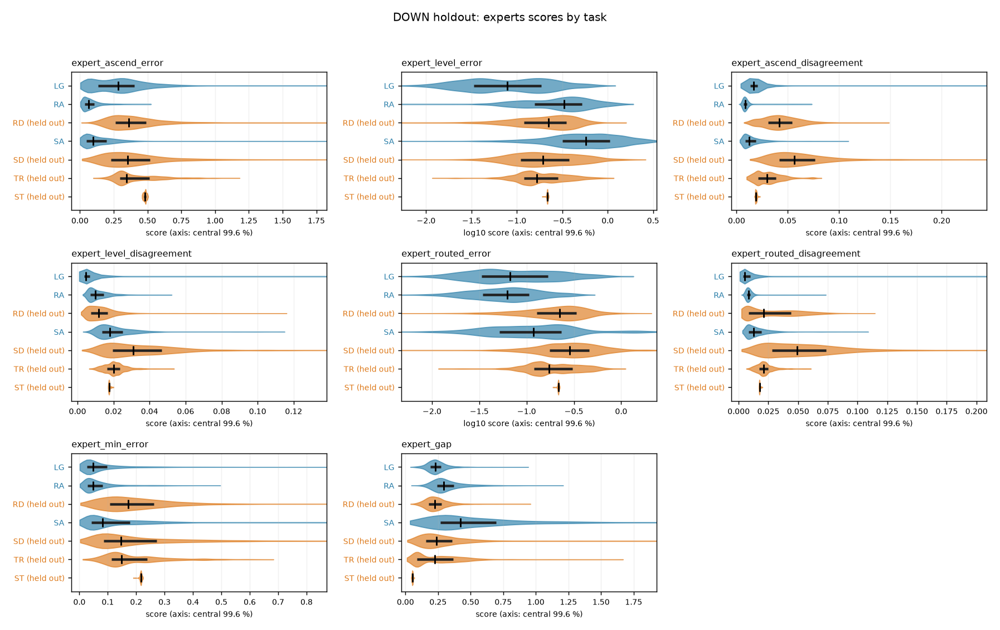

### baselines

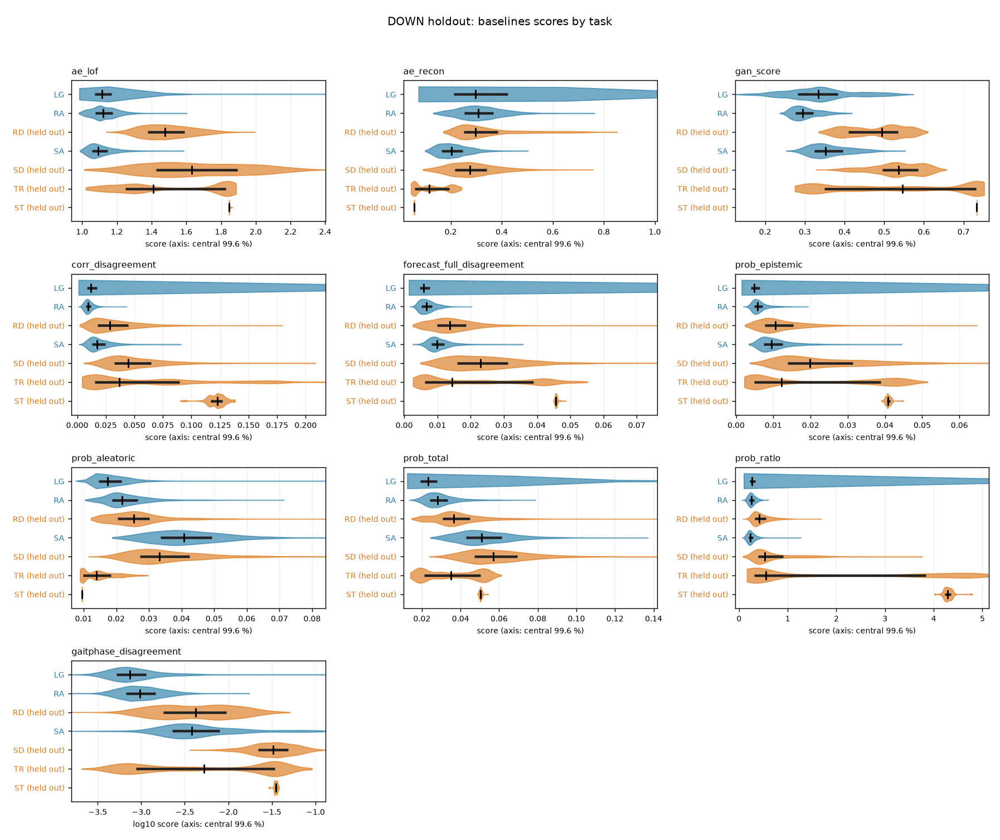

In [9]:
from IPython.display import Image
RECOMPUTE_SCORES = False
if RECOMPUTE_SCORES:
    import aw_scores, aw_plots
    ss = aw_scores.collect(HOLDOUT)
    summary = aw_scores.summarize(ss)
    aw_scores.write(ss, summary); aw_plots.all_groups(ss)
csv = RESULTS_AW / 'score_summary.csv'
if csv.exists():
    summary = pd.read_csv(csv)
    auc_cols = [c for c in summary.columns if c.startswith('AUROC')]
    display(summary[['score', 'windows', *auc_cols]].round(4).style.hide(axis='index'))
    display(Markdown('**Per-mode medians (each score in its own units):**'))
    display(summary[['score'] + [c for c in summary.columns if c.startswith('median ')]].round(4).style.hide(axis='index'))
    for group in ('novelty', 'regime', 'forecast', 'experts', 'baselines'):
        png = RESULTS_AW / f'spread_{group}.png'
        display(Markdown(f'### {group}'))
        display(Image(filename=str(png), width=1000)) if png.exists() else print('not available yet:', png.name)
else:
    print('No tracked results yet:', csv)

## Making the dangerous cells fire: injected sensor faults

The held-out regime under `DOWN` turned out to be the **OOD-safe** case: unfamiliar to LOF, confidently
routed to a known regime, and still forecast acceptably. Nothing in the dataset is dangerous, so the
other cell of the novelty × health grid is populated here by construction: level-ground test windows
with a sensor fault injected into the **input only** (dead left-thigh IMU, a frozen right-thigh IMU, IMU noise at twice each channel's spread, gyro spikes, a 100 ms left-leg
delay), persistently across whole trials so the causal median filter behaves as in deployment. The
forecast target is the true future encoder reading, so realized error measures what the corrupted
input does to the prediction. A constant encoder offset is deliberately not among them: it is a
calibration error rather than a dynamic fault, and the future reading would carry the same bias.

The same five faults are applied to ramp-descent windows too, so all four cells of the grid exist
on the same participants: **ID-safe** (level ground), **ID-dangerous** (level ground + fault),
**OOD-safe** (ramp descent), **OOD-dangerous** (ramp descent + fault). Every window goes through
the same pipeline: LOF on the encoder latent, reconstruction NLL, the regime probe, the unrouted
forecast ensemble and the **routed regime experts**, whose error is the health axis in the
quadrant figure so that the regime has its say. AUROCs are against ID-safe and against OOD-safe.

**AUROC of each condition against ID-safe** (0.5 = indistinguishable; a cell is blank against itself):

condition,windows,novelty_lof32,recon_nll,regime_entropy,forecast_disagreement,forecast_error,expert_routed_error
LG (ID-safe),12264,nan,nan,nan,nan,nan,nan
RD (OOD-safe),12300,0.981000,0.499000,0.556000,0.882000,0.927000,0.899000
LG + dead_left_imu (ID-dangerous),12264,0.989000,0.915000,0.686000,0.983000,0.904000,0.839000
RD + dead_left_imu (OOD-dangerous),12300,0.989000,0.867000,0.480000,0.985000,0.937000,0.944000
LG + frozen_right_imu (ID-dangerous),12264,0.989000,0.931000,0.453000,0.973000,0.877000,0.920000
RD + frozen_right_imu (OOD-dangerous),12300,0.989000,0.816000,0.386000,0.979000,0.947000,0.955000
LG + imu_noise (ID-dangerous),12264,0.966000,0.989000,0.323000,0.939000,0.721000,0.670000
RD + imu_noise (OOD-dangerous),12300,0.989000,0.989000,0.450000,0.976000,0.917000,0.882000
LG + gyro_spikes (ID-dangerous),12264,0.989000,0.989000,0.018000,0.988000,0.758000,0.804000
RD + gyro_spikes (OOD-dangerous),12300,0.989000,0.989000,0.035000,0.989000,0.853000,0.838000


**AUROC of each condition against OOD-safe** (0.5 = indistinguishable; a cell is blank against itself):

condition,windows,novelty_lof32,recon_nll,regime_entropy,forecast_disagreement,forecast_error,expert_routed_error
LG (ID-safe),12264,0.019000,0.501000,0.444000,0.118000,0.073000,0.101000
RD (OOD-safe),12300,nan,nan,nan,nan,nan,nan
LG + dead_left_imu (ID-dangerous),12264,0.917000,0.914000,0.659000,0.969000,0.451000,0.338000
RD + dead_left_imu (OOD-dangerous),12300,0.975000,0.872000,0.403000,0.982000,0.576000,0.645000
LG + frozen_right_imu (ID-dangerous),12264,0.988000,0.931000,0.383000,0.926000,0.346000,0.526000
RD + frozen_right_imu (OOD-dangerous),12300,0.998000,0.830000,0.315000,0.955000,0.546000,0.643000
LG + imu_noise (ID-dangerous),12264,0.308000,1.000000,0.239000,0.747000,0.153000,0.162000
RD + imu_noise (OOD-dangerous),12300,0.914000,1.000000,0.382000,0.945000,0.447000,0.431000
LG + gyro_spikes (ID-dangerous),12264,1.000000,1.000000,0.001000,0.992000,0.181000,0.264000
RD + gyro_spikes (OOD-dangerous),12300,1.000000,1.000000,0.005000,0.999000,0.280000,0.323000


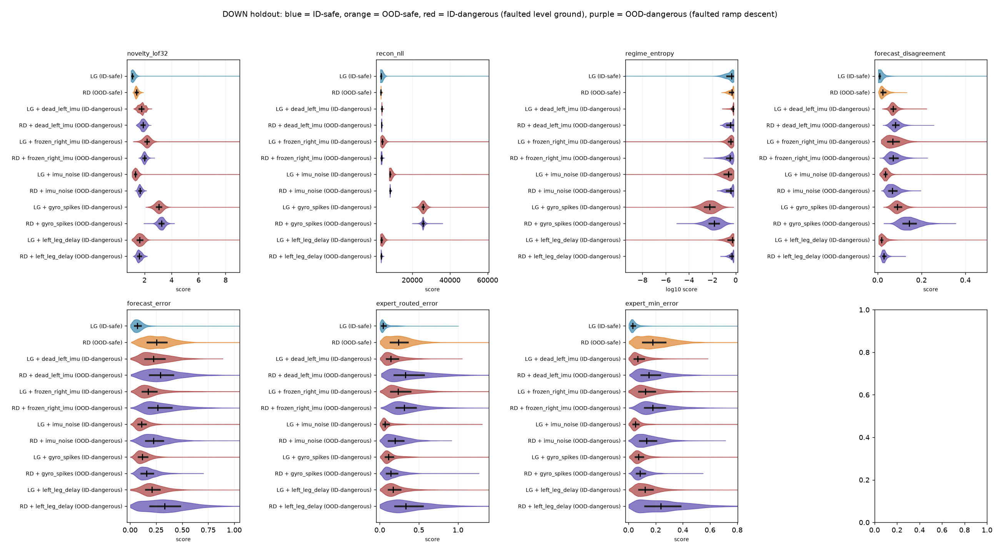

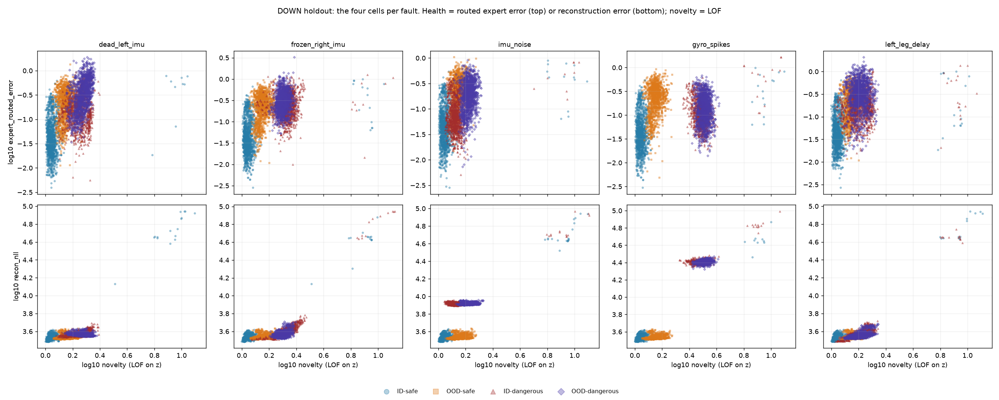

In [10]:
fs = RESULTS_AW / 'faults_summary.csv'
if fs.exists():
    fsum = pd.read_csv(fs)
    keys = ['novelty_lof32', 'recon_nll', 'regime_entropy', 'forecast_disagreement', 'forecast_error', 'expert_routed_error']
    for against in ('ID-safe', 'OOD-safe'):
        cols = [f'AUROC vs {against}: {k}' for k in keys if f'AUROC vs {against}: {k}' in fsum]
        display(Markdown(f'**AUROC of each condition against {against}** (0.5 = indistinguishable; a cell is blank against itself):'))
        display(fsum[['condition', 'windows', *cols]].rename(columns=lambda c: c.replace(f'AUROC vs {against}: ', '')).round(3).style.hide(axis='index'))
    for name in ('faults_spread.png', 'faults_quadrants.png'):
        png = RESULTS_AW / name
        display(Image(filename=str(png), width=1000)) if png.exists() else print('missing', name)
else:
    print('Run `python ml/awareness/faults.py --holdout DOWN --write` to create', fs.name)

### The four cells in three dimensions

Novelty (LOF on the encoder latent), the **autoencoder's reconstruction error** (the decoder's NLL
of the window, not a forecast) and the **routed expert forecast error** as three axes, all log10.
Pick a fault with the selector; each cell keeps its colour. Rotate to see that the dangerous cells
leave the safe ones along the reconstruction axis while the forecast-error axis mostly does not
separate them.

In [11]:
import plotly.graph_objects as go
from _umap_exploration import show, PLOTLY_CONFIG
fsc = RESULTS_AW / 'faults_scores.parquet'
if fsc.exists():
    fdf = pd.read_parquet(fsc)
    cells = {'ID-safe': ('#287da8', 'circle'), 'OOD-safe': ('#dd791a', 'square'), 'ID-dangerous': ('#a32d2d', 'cross'), 'OOD-dangerous': ('#4a3aa7', 'diamond')}
    axes3 = ('novelty_lof32', 'recon_nll', 'expert_routed_error')
    faults = sorted({c[c.index('+ ') + 2:c.rfind(' (')] for c in fdf.condition.unique() if '+' in c})
    rng = np.random.default_rng(0); fig = go.Figure(); groups = []; ranges = []
    CLIP = (0.5, 99.5)   # axis ranges span this percentile band of the plotted points; nothing is dropped from the tables
    for fi, fault in enumerate(faults):
        conds = {'ID-safe': 'LG (ID-safe)', 'OOD-safe': 'RD (OOD-safe)',
                 'ID-dangerous': f'LG + {fault} (ID-dangerous)', 'OOD-dangerous': f'RD + {fault} (OOD-dangerous)'}
        idx, shown = [], []
        for cell, cond in conds.items():
            g = fdf[fdf.condition == cond]; pick = rng.choice(len(g), min(1500, len(g)), replace=False); g = g.iloc[pick]
            color, symbol = cells[cell]
            xyz = np.log10(g[list(axes3)].to_numpy()); shown.append(xyz)
            fig.add_trace(go.Scatter3d(x=xyz[:, 0], y=xyz[:, 1], z=xyz[:, 2], mode='markers',
                                       name=cell, visible=(fi == 0), legendgroup=cell, showlegend=True,
                                       marker=dict(size=2.4, color=color, symbol=symbol, opacity=.55),
                                       text=g['subject'] + ' · ' + g['trial'], hovertemplate='%{text}<extra>' + cell + '</extra>'))
            idx.append(len(fig.data) - 1)
        groups.append(idx)
        allpts = np.concatenate(shown); lo, hi = np.percentile(allpts, CLIP[0], axis=0), np.percentile(allpts, CLIP[1], axis=0)
        pad = .05 * (hi - lo); ranges.append([[float(l - p), float(h + p)] for l, h, p in zip(lo, hi, pad)])
    def layout_for(fi, fault):
        r = ranges[fi]
        return {'title.text': f'Four cells, fault: {fault}  (axes clipped to the central {CLIP[1] - CLIP[0]:.0f} % of plotted windows)',
                'scene.xaxis.range': r[0], 'scene.yaxis.range': r[1], 'scene.zaxis.range': r[2]}
    buttons = [dict(label=fault, method='update', args=[{'visible': [i in set(groups[fi]) for i in range(len(fig.data))]}, layout_for(fi, fault)])
               for fi, fault in enumerate(faults)]
    fig.update_layout(title=layout_for(0, faults[0])['title.text'], template='plotly_white', height=680, margin=dict(l=0, r=0, t=90, b=0),
                      scene=dict(xaxis=dict(title='log10 LOF novelty', range=ranges[0][0]), yaxis=dict(title='log10 AE reconstruction NLL', range=ranges[0][1]),
                                 zaxis=dict(title='log10 routed expert forecast error', range=ranges[0][2]), aspectmode='cube'),
                      updatemenus=[dict(type='dropdown', x=0, xanchor='left', y=1.1, yanchor='top', buttons=buttons)],
                      legend=dict(title='cell (click to hide, double-click to isolate)', itemsizing='constant'))
    show(fig, 'faults_four_cells_3d', SAVE_HTML)
else:
    print('No fault scores yet:', fsc)

Standalone interactive copy: notebooks/model_exploration/interactive/faults_four_cells_3d.html


## What other targets could make the regime matter? A label inventory

Regime conditioning failed because the 200 ms hip-angle target is locally continuous and
therefore regime-insensitive. The raw trials carry more than the 16 channels: inverse-kinematics
joint angles, inverse-dynamics **joint moments**, per-leg gait phase from heel strike and toe off,
ground reaction forces and a pelvis IMU. `ml/awareness/results/dataset_labels.md` inventories them
and their coverage; the table below is the per-mode coverage of the sampled trials. Gait phase and
moments are valid on exactly the samples where a force plate was struck, and stairs carry one or
two labelled strides per short trial. Candidate regime-dependent targets: the coming stride's
duration, stance fraction, hip flexion/extension peaks (available from the encoder itself, no lab
labels needed), and the hip moment, which is also the fallback controller's own quantity.

In [12]:
cov = AW / 'results' / 'dataset_label_coverage.csv'
if cov.exists():
    lab = pd.read_csv(cov)
    display(lab.groupby('mode').agg(trials=('trial', 'size'), seconds=('seconds', 'median'),
        gait_phase_valid_L=('gp_valid_l', 'mean'), gait_phase_valid_R=('gp_valid_r', 'mean'),
        strides_L=('strides_l', 'median'), stride_time_s=('stride_s_l', 'median'),
        moment_valid_L=('moment_valid_l', 'mean'), hip_range_rad=('hip_range_l', 'median')).round(3))
else:
    print('No coverage table yet:', cov)

,trials,seconds,gait_phase_valid_L,gait_phase_valid_R,strides_L,stride_time_s,moment_valid_L,hip_range_rad
mode,,,,,,,,
LG,12,32.000,0.812,0.764,21.0,1.235,0.812,0.829
RA,12,32.000,0.898,0.917,26.5,1.087,0.898,1.090
RD,12,32.000,0.843,0.853,27.0,1.000,0.843,0.685
SA,12,5.738,0.402,0.403,1.0,1.220,0.402,0.997
SD,12,5.190,0.346,0.308,2.0,1.030,0.346,0.626
ST,5,32.000,0.938,0.938,0.0,NaN,0.938,0.017
TR,24,21.278,0.909,0.909,9.0,1.035,0.909,0.864


## How to read this, and what comes next

- **Novelty** answers "is this unlike LG/RA/SA?". The held-out modes should sit to the right of the
  trained-on ones; how far, and whether standing and transitions behave like the descents, is what
  the violins show.
- **Regime** cannot say "descend". Watch whether entropy rises on RD/SD relative to ID, and which
  known regime absorbs them; a confident wrong assignment is itself a finding.
- **Reliability** is two axes: disagreement now, realized error later. Their joint reading
  (confident and wrong) is the one a single score cannot express.
- **Baselines** show where each existing model's score puts the same windows.

No score is thresholded here. Fusion, thresholds at a declared false-alarm budget, seeds and the
other regime holdouts (ascending, level) are the next steps, in that order.

## Ablation: the pelvis IMU as six more input channels

Notebook 09's raw-space check said the pelvis IMU adds almost no task structure (k-NN task accuracy
0.600 → 0.615 with participants held out). The question that matters here is different: does a
learned encoder get anything out of it for **novelty** under the regime holdout? So Stage A and
Stage B are rerun unchanged on a 22-channel build of the same windows
(`ml/LOTO/build_data.py --channels pelvis`: the 16 channels with the *same* scaler numbers, plus
`pelvis_accel_xyz` and `pelvis_gyro_xyz` with their own LG/RA/RD-training scaler). Same β = 0 encoder,
same settings and seed, same LOF reference size, same test windows; the arrays were cut on the cluster
from the raw trials (`ml/awareness/slurm/pelvis_build.sbatch`) and the runs sit beside the 16-channel
ones as `encoder_pelvis/` and `regime_pelvis/`.

Read the table as a paired comparison: every AUROC is on the identical windows, so a difference of a
few thousandths is seed noise and a difference on one held-out mode is where to look.

,OOD vs ID · 16 ch,OOD vs ID · 22 ch,RD vs ID · 16 ch,RD vs ID · 22 ch,SD vs ID · 16 ch,SD vs ID · 22 ch,ST vs ID · 16 ch,ST vs ID · 22 ch,TR vs ID · 16 ch,TR vs ID · 22 ch
score,,,,,,,,,,
"LOF, 32-D latent",0.974,0.948,0.979,0.950,0.983,0.968,0.998,0.998,0.882,0.822
"LOF, PCA-12",0.956,0.947,0.952,0.948,0.983,0.964,0.998,0.998,0.838,0.843
"LOF, PCA-16",0.958,0.954,0.956,0.951,0.981,0.973,0.998,0.998,0.839,0.866
reconstruction NLL,0.486,0.611,0.572,0.699,0.467,0.623,0.003,0.000,0.104,0.093


,input channels,epochs run,best epoch,best val loss,seed,hours,logistic probe ID accuracy,mlp probe ID accuracy
encoder,,,,,,,,
16 channels (thigh + encoders),16.0,29.0,24.0,3467.779,0.0,0.659,0.891,0.911
22 channels (+ pelvis IMU),22.0,30.0,25.0,4811.431,0.0,0.727,0.927,0.946


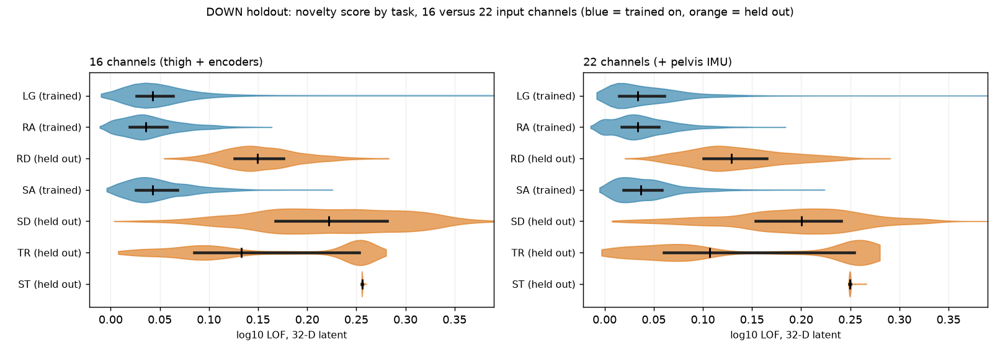

In [13]:
pa = RESULTS_AW / 'pelvis_ablation.csv'
if pa.exists():
    pab = pd.read_csv(pa)
    wide = pab.pivot(index='score', columns='encoder', values=[c for c in pab.columns if c.startswith('AUROC')])
    wide.columns = [f'{a.replace("AUROC ", "")} · {b.split(" ")[0]} ch' for a, b in wide.columns]
    display(wide.loc[['LOF, 32-D latent', 'LOF, PCA-12', 'LOF, PCA-16', 'reconstruction NLL']].round(3))
    display(pd.read_csv(RESULTS_AW / 'pelvis_ablation_runs.csv', index_col=0).round(3))
    png = RESULTS_AW / 'pelvis_ablation.png'
    display(Image(filename=str(png), width=1000)) if png.exists() else print('missing', png.name)
else:
    print('Run `python ml/awareness/pelvis_ablation.py --holdout DOWN --write` after pulling encoder_pelvis/ to create', pa.name)

### Interactive views of the 22-channel encoder's test latents

The same construction as the 16-channel views in Stage A: UMAP and PCA fitted on the **in-distribution**
test latents (LG, RA, SA) of `encoder_pelvis`, every task transformed in, raw latent coordinates in the
third panel; same point budget and seed, task colours fixed. Compare with the Stage A views above: the
question is whether the four held-out modes sit further from, or closer to, the trained-on gait once the
pelvis IMU is in the input. The AUROC table says closer.

In [14]:
ENC_PELVIS = RUNS_AW / 'encoder_pelvis'
if (ENC_PELVIS / 'latents_test.npz').exists():
    enc_pelvis_views = ae_latent_views(ENC_PELVIS, dims=VIEW_DIMS, projections=PROJECTIONS, latent_dims=LATENT_DIMS,
                                       max_points=MAX_POINTS, seed=VIEW_SEED, save_html=SAVE_HTML,
                                       title='22-channel encoder latent (32-D)')
else:
    print('Ablation run not pulled yet:', ENC_PELVIS)

Standalone interactive copy: notebooks/model_exploration/interactive/ae_encoder_pelvis_views_2d.html


Standalone interactive copy: notebooks/model_exploration/interactive/ae_encoder_pelvis_views_3d.html


In [15]:
source_links(['ml/awareness/README.md', 'ml/awareness/encoder.py', 'ml/awareness/regime.py', 'ml/awareness/forecast.py', 'ml/awareness/experts.py', 'ml/awareness/faults.py', 'ml/awareness/aw_scores.py', 'ml/awareness/aw_plots.py', 'ml/LOTO/splits.py'])

Implementation sources: [README.md](../../ml/awareness/README.md), [encoder.py](../../ml/awareness/encoder.py), [regime.py](../../ml/awareness/regime.py), [forecast.py](../../ml/awareness/forecast.py), [experts.py](../../ml/awareness/experts.py), [faults.py](../../ml/awareness/faults.py), [aw_scores.py](../../ml/awareness/aw_scores.py), [aw_plots.py](../../ml/awareness/aw_plots.py), [splits.py](../../ml/LOTO/splits.py)